# This is heart disease prediction project 
we are going to predict based on the data whether someone has heart disease or not 

* 1- problem defination
* 2- Data
* 3-evaluate
* 4-features
* 5-model
* 6-experimentations


# 1- problem defination 
> based on the given data we haave to predict that tha patient has the heart disease or not

# 2- data
> we have the data and loaded it already


# 3- evaluate
> in intitial stages we need to make sure if out model gives us accuracy of 95% 

# 4- Features
what features are import and what fearutes columns are means to be : describing what

age
Patient's Age


sex
Patient's Gender( 1='male', 0='female')


cp
Patient's CP Level


trestbps
Patient's Trest BPS Level


chol
Patient's Cholestrol Level


fbs
Patient's FBS Level


restecg
Patient's Resting ECG Levels


thalach
Patient's Thalach Levels max heart beat reached


exang
Patient's Exang Levels


oldpeak
Patient's Old Peak History Recorded


slope
Patient's Slope Levels


ca
Patient's CA Levels


thal
Patient's Thal Levels


target
0 - Healthy Individual 1 - Heart-Disease Patient

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Importing sklearn models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Importing Evaluation Libraries
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import RocCurveDisplay

# Evaluation metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

# exploring the data at initial stages
* what probelm i am going to solve
* what kind of data i have
* does this data have missing values
* Are there any outliers, sporious vectors
* can we add or remove some of the features

In [5]:
df=pd.read_csv('final project dataset heart disease.csv')
df.shape # tells number of rows and columns
               

(303, 14)

In [6]:
df.head() #checking few rwos of starting

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [7]:
df.tail()#checking few rwos of ending

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [8]:
df['target'].value_counts()

target
1    165
0    138
Name: count, dtype: int64

<Axes: xlabel='target'>

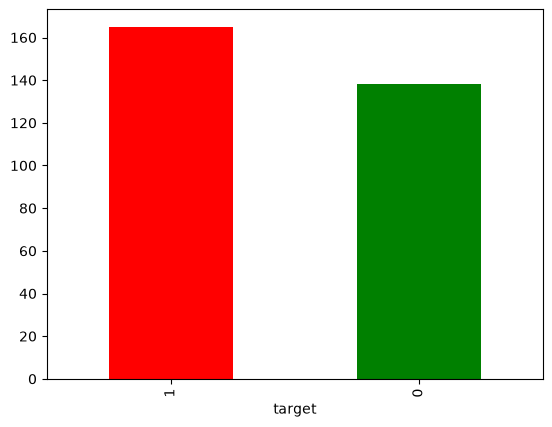

In [9]:
df['target'].value_counts().plot(kind='bar' , color=['red' , 'green'])

In [10]:
# checking missin gvalues
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [11]:
# checking statistics
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [12]:
df.sex.value_counts()

sex
1    207
0     96
Name: count, dtype: int64

In [13]:
len(df)

303

In [14]:
207/303 # 68 percent male

0.6831683168316832

In [15]:
pd.crosstab(df.target,df.sex)

sex,0,1
target,,
0,24,114
1,72,93


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

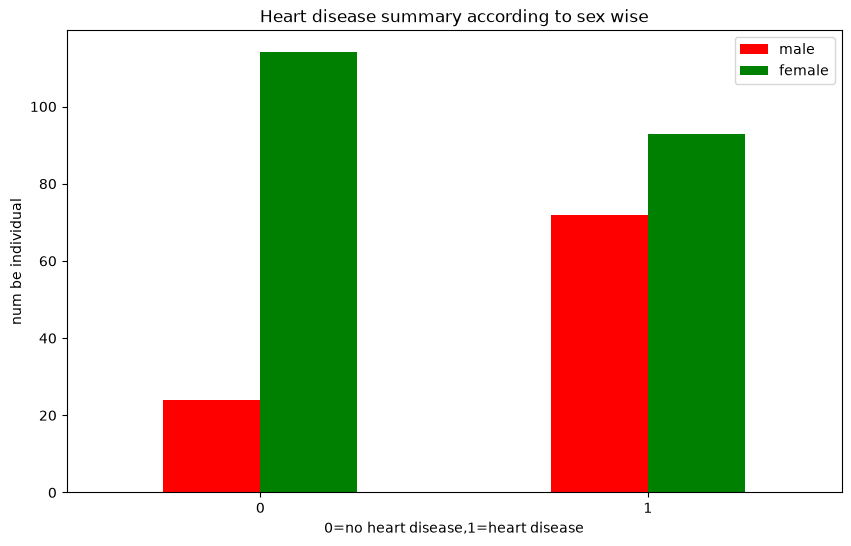

In [16]:
pd.crosstab(df.target,df.sex).plot(kind='bar',
                                   figsize=(10,6),
                                   color=['red','green'])
plt.title('Heart disease summary according to sex wise') # Adds a title to the graph
plt.xlabel('0=no heart disease,1=heart disease') # naming the X-axis
plt.ylabel('num be individual') # Naming the Y-axis
plt.legend(['male','female']) # Shows labels for different lines/bars
plt.xticks(rotation=0) # controls the labels/ticks on the X-axis.
                                   

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40]),
 [Text(0, 0, '29'),
  Text(1, 0, '34'),
  Text(2, 0, '35'),
  Text(3, 0, '37'),
  Text(4, 0, '38'),
  Text(5, 0, '39'),
  Text(6, 0, '40'),
  Text(7, 0, '41'),
  Text(8, 0, '42'),
  Text(9, 0, '43'),
  Text(10, 0, '44'),
  Text(11, 0, '45'),
  Text(12, 0, '46'),
  Text(13, 0, '47'),
  Text(14, 0, '48'),
  Text(15, 0, '49'),
  Text(16, 0, '50'),
  Text(17, 0, '51'),
  Text(18, 0, '52'),
  Text(19, 0, '53'),
  Text(20, 0, '54'),
  Text(21, 0, '55'),
  Text(22, 0, '56'),
  Text(23, 0, '57'),
  Text(24, 0, '58'),
  Text(25, 0, '59'),
  Text(26, 0, '60'),
  Text(27, 0, '61'),
  Text(28, 0, '62'),
  Text(29, 0, '63'),
  Text(30, 0, '64'),
  Text(31, 0, '65'),
  Text(32, 0, '66'),
  Text(33, 0, '67'),
  Text(34, 0, '68'),
  Text(35, 0, '69'),
  Text(36, 0, '70'),
  Text(37, 0, '71'),
  Text(38, 0, '74'),
 

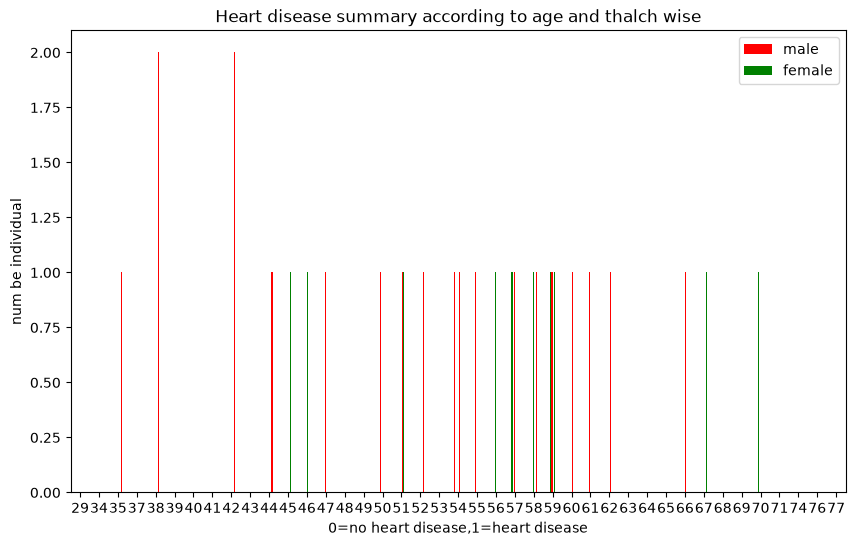

In [17]:
pd.crosstab(df.age,df.thalach).plot(kind='bar',
                                   figsize=(10,6),
                                   color=['red','green'])
plt.title('Heart disease summary according to age and thalch wise') 
plt.xlabel('0=no heart disease,1=heart disease') 
plt.ylabel('num be individual') 
plt.legend(['male','female'])
plt.xticks(rotation=0) 

# its showing array beacuse we have not chose the right plot 

# correcting it 

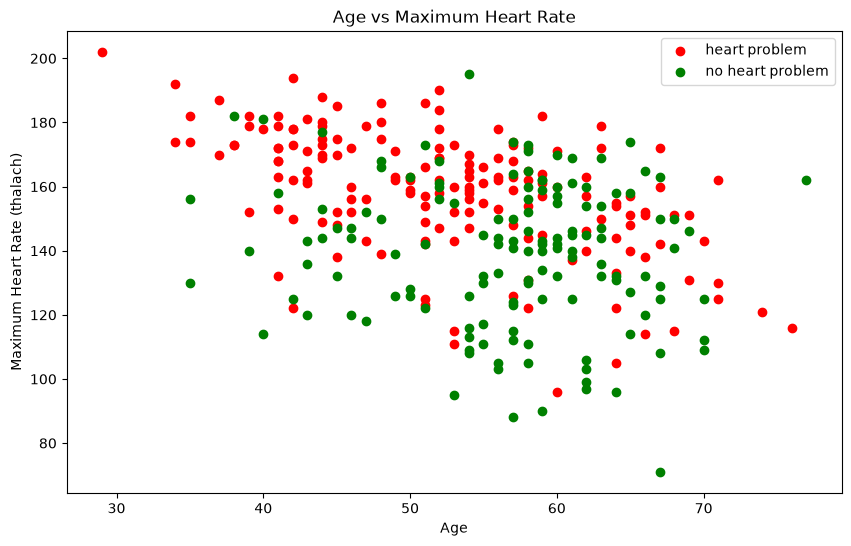

In [18]:
# finding patterns in data using scatter plot

plt.figure(figsize=(10,6))

# creating scatter plot
# Target = 1
plt.scatter(
    df.age[df.target == 1],
    df.thalach[df.target == 1],
    c="red",
    label="heart problem"
)

# Target = 0
plt.scatter(
    df.age[df.target == 0],
    df.thalach[df.target == 0],
    c="green",
    label="no heart problem"
)

plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate (thalach)")
plt.title("Age vs Maximum Heart Rate")
plt.legend()
plt.show()


In [19]:
# create histogram to see age distribution


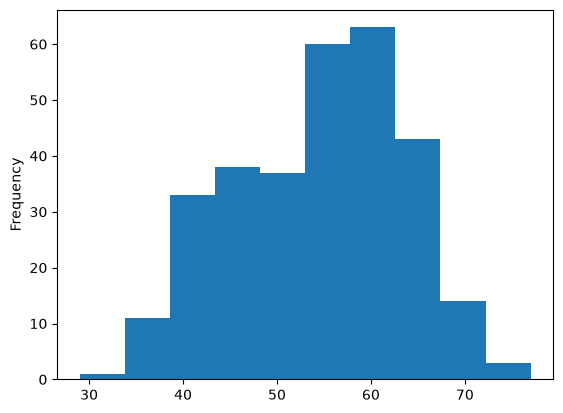

In [20]:
df.age.plot.hist();
# result yh nikla ka zada bari age wala logon ko zada heart ki bemari ha 
# 1 histogram hama yh btata ha ka ap ka data ka andr kitna outliers ha
# gausian surface bn rhi ha 

# now checking with chest pain 

# description of chest pain
* value 0 = typical angina (chest pain due to decrease of blood preasure)
* value 1 = atypical angina (not related to heart problem)
* calue 2 = non-anginal pain (not heart related)
* value 3 = asymptomatic (not showing heart problem)

In [21]:
df.cp.value_counts()

cp
0    143
2     87
1     50
3     23
Name: count, dtype: int64

In [22]:
pd.crosstab(df.cp,df.target)

target,0,1
cp,,
0,104,39
1,9,41
2,18,69
3,7,16


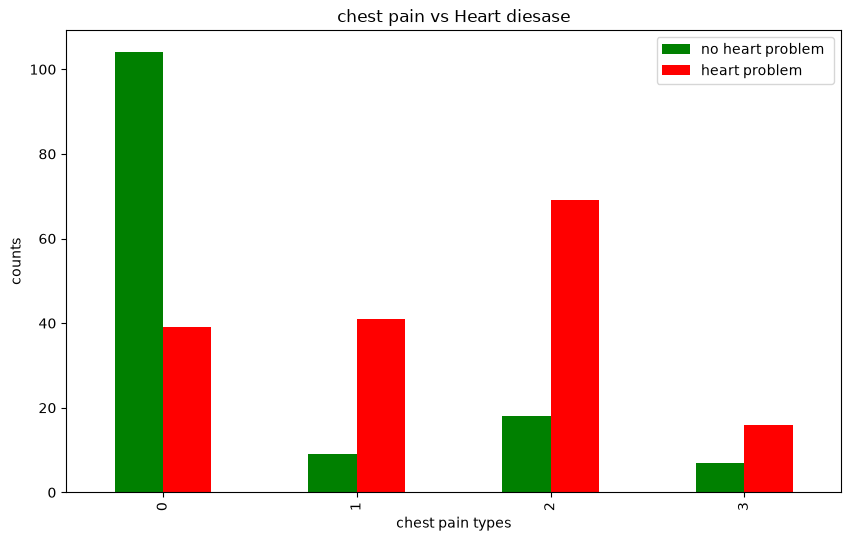

In [23]:
pd.crosstab(df.cp,df.target).plot(kind='bar',
                                  figsize=(10,6),
                                  color=['green','red'])
plt.title('chest pain vs Heart diesase') 
plt.xlabel('chest pain types') 
plt.ylabel('counts') 
plt.legend(['no heart problem ','heart problem '])    

# trend is moving upwards 

# coorealaation MAtrix

In [24]:
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [25]:
df.corr()
# diagnoal value hamesha 1 nzr aye g
# 2 kism ka nzr ayein ga co realtion positive and negative 1 ka ilawa
# positive ka mtlb ha agr ik value postive ha to agli postive ha wo increase kre g 
# negative ka mtlv ha age ik value positve ha to agli negative ha 
# eg. cp ka relation agr thalach sa kiya jaye to positve relation ha chest pain incerase ka sath sath thalach means heart rate bhi brha ga
# eg. cp ka age ka sath raelation aa rha ha negative ka

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.098447,-0.068653,0.279351,0.213678,0.121308,-0.116211,-0.398522,0.096801,0.210013,-0.168814,0.276326,0.068001,-0.225439
sex,-0.098447,1.000000,-0.049353,-0.056769,-0.197912,0.045032,-0.058196,-0.044020,0.141664,0.096093,-0.030711,0.118261,0.210041,-0.280937
cp,-0.068653,-0.049353,1.000000,0.047608,-0.076904,0.094444,0.044421,0.295762,-0.394280,-0.149230,0.119717,-0.181053,-0.161736,0.433798
trestbps,0.279351,-0.056769,0.047608,1.000000,0.123174,0.177531,-0.114103,-0.046698,0.067616,0.193216,-0.121475,0.101389,0.062210,-0.144931
chol,0.213678,-0.197912,-0.076904,0.123174,1.000000,0.013294,-0.151040,-0.009940,0.067023,0.053952,-0.004038,0.070511,0.098803,-0.085239
fbs,0.121308,0.045032,0.094444,0.177531,0.013294,1.000000,-0.084189,-0.008567,0.025665,0.005747,-0.059894,0.137979,-0.032019,-0.028046
restecg,-0.116211,-0.058196,0.044421,-0.114103,-0.151040,-0.084189,1.000000,0.044123,-0.070733,-0.058770,0.093045,-0.072042,-0.011981,0.137230
thalach,-0.398522,-0.044020,0.295762,-0.046698,-0.009940,-0.008567,0.044123,1.000000,-0.378812,-0.344187,0.386784,-0.213177,-0.096439,0.421741
exang,0.096801,0.141664,-0.394280,0.067616,0.067023,0.025665,-0.070733,-0.378812,1.000000,0.288223,-0.257748,0.115739,0.206754,-0.436757
oldpeak,0.210013,0.096093,-0.149230,0.193216,0.053952,0.005747,-0.058770,-0.344187,0.288223,1.000000,-0.577537,0.222682,0.210244,-0.430696


# lets draw corelation map

<Axes: >

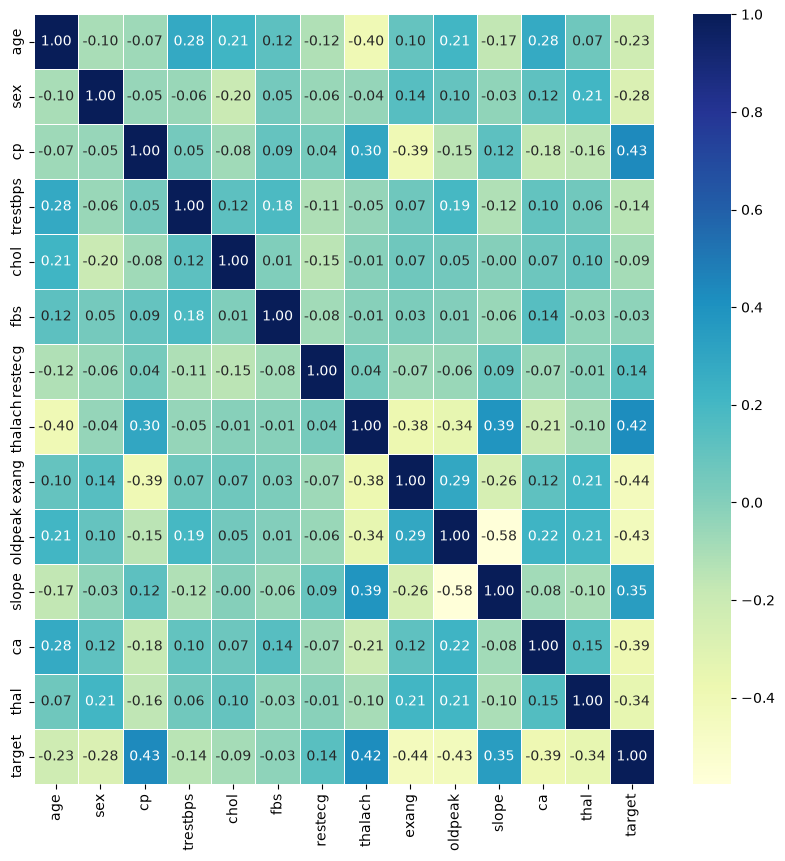

In [26]:
cor_map = df.corr()

plt.figure(figsize=(10, 10))

sns.heatmap(
    cor_map,
    annot=True,
    linewidths=0.5,
    fmt=".2f",
    cmap="YlGnBu"
)
# right side pr jo bar ha us ki value 1 strong corealtion show kr rhi ha jab ka down ma 0.4 weak show kr rha h clor dull ha us ka
# cp ka target ka sath realtion positive ha 

# 5- Modeling

In [27]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [28]:
# split data into test and train


In [29]:
x=df.drop("target",axis=1)
y=df["target"]

In [30]:
# using random seed so that other could produce the same result
np.random.seed(7)
# split into test and train
X_train,X_test,Y_train,Y_test = train_test_split(x,y,test_size=0.2)

In [31]:
len(X)

NameError: name 'X' is not defined

In [32]:
len(X_train)

242

# The models we are going to use 
1. K-Nearest Neighbours classifier
2. randomforestclassifier
3. Logistic REgression

In [33]:
models = {
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Logistic Regression": LogisticRegression()
}

# creating function to evaluate the models
def fit_and_score(models, X_train, X_test, Y_train, Y_test):
    np.random.seed(7)

    # make dictionary to score the models
    model_score = {}

    # looping through the models
    for name, model in models.items():
        model.fit(X_train, Y_train)

        # evaluate the model and append it to score
        model_score[name] = model.score(X_test, Y_test)

    return model_score

model_scores = fit_and_score(
    models=models,
    X_train=X_train,
    X_test=X_test,
    Y_train=Y_train,
    Y_test=Y_test
)

model_scores

In [34]:
model_scores = fit_and_score(
    models=models,
    X_train=X_train,
    X_test=X_test,
    Y_train=Y_train,
    Y_test=Y_test
)

model_scores

# according to result accurasy should be nearest to 95 percent

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'KNN': 0.5573770491803278,
 'Random Forest': 0.7213114754098361,
 'Logistic Regression': 0.7377049180327869}

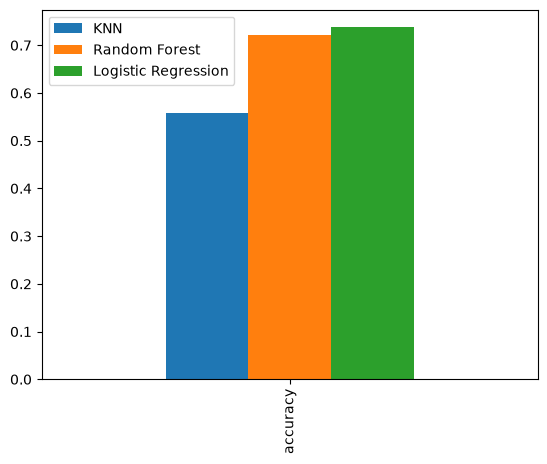

In [35]:
model_compare= pd.DataFrame(model_scores,index=["accuracy"])

model_compare.plot.bar();                      

# Improving and tunning the models
  Universal methods used for all  classification problems
   * hypermeter tunning
   * features improving
 
  # Advanced level
     *confusion matrix
     *cross_validation
     *precision
     *recall
     *f1
     *classification Report
     *ROC curve

In [36]:
KNN=KNeighborsClassifier()
KNN.set_params()

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None


In [37]:
train_scores = []
test_scores = []

# create range to be tested for n_neighbors
n_neighbors = range(1, 30)

# KNN instance
KNN = KNeighborsClassifier()

# looping through the range
for i in n_neighbors:

    # set the number of neighbors
    KNN.set_params(n_neighbors=i)

    # fit the model
    KNN.fit(X_train, Y_train)

    # update training score
    train_scores.append(KNN.score(X_train, Y_train))

    # update test score
    test_scores.append(KNN.score(X_test, Y_test))

In [38]:
train_scores

[1.0,
 0.8099173553719008,
 0.7768595041322314,
 0.756198347107438,
 0.7603305785123967,
 0.731404958677686,
 0.743801652892562,
 0.7148760330578512,
 0.71900826446281,
 0.731404958677686,
 0.7272727272727273,
 0.7231404958677686,
 0.731404958677686,
 0.71900826446281,
 0.7148760330578512,
 0.6900826446280992,
 0.7272727272727273,
 0.71900826446281,
 0.7107438016528925,
 0.7066115702479339,
 0.7024793388429752,
 0.7024793388429752,
 0.7107438016528925,
 0.6900826446280992,
 0.7107438016528925,
 0.7066115702479339,
 0.7107438016528925,
 0.7066115702479339,
 0.7066115702479339]

In [39]:
test_scores

[0.6065573770491803,
 0.6557377049180327,
 0.6229508196721312,
 0.6229508196721312,
 0.5573770491803278,
 0.639344262295082,
 0.6721311475409836,
 0.6557377049180327,
 0.6065573770491803,
 0.6065573770491803,
 0.6229508196721312,
 0.639344262295082,
 0.6557377049180327,
 0.6557377049180327,
 0.6557377049180327,
 0.6557377049180327,
 0.6721311475409836,
 0.6721311475409836,
 0.6557377049180327,
 0.6721311475409836,
 0.6721311475409836,
 0.6721311475409836,
 0.6721311475409836,
 0.7049180327868853,
 0.6885245901639344,
 0.6885245901639344,
 0.7049180327868853,
 0.7049180327868853,
 0.6557377049180327]

# plot the accuracy score

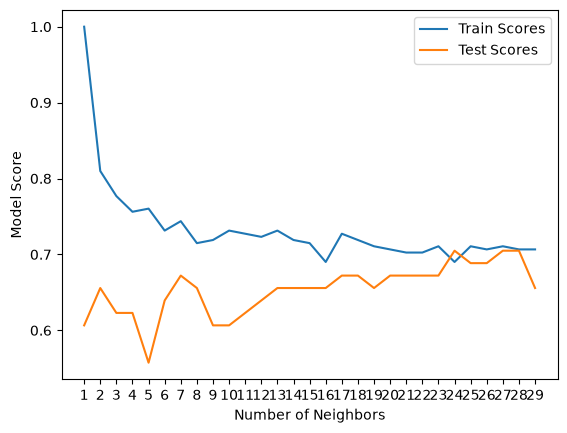

Max KNN score: 70.49%


In [40]:
plt.plot(n_neighbors, train_scores, label="Train Scores")
plt.plot(n_neighbors, test_scores, label="Test Scores")

plt.xticks(np.arange(1, 30, 1))

plt.xlabel("Number of Neighbors")
plt.ylabel("Model Score")
plt.legend()
plt.show()

print(f"Max KNN score: {max(test_scores) * 100:.2f}%")

# accuracy 70.49 is not equal to 95 percent false ho gya yh  

# Hyperparameter tunning using Randomaized Search CV
* Random Forest
* Logistic Regression

In [41]:
LR_hp = {
    "C": np.logspace(-4, 4, 29),
    "solver": ["liblinear", "lbfgs"]
}
RFC_hp = {
    "n_estimators": np.arange(10, 1600, 100),
    "max_depth": [None, 3, 5, 6, 10],
    "min_samples_leaf": np.arange(1, 20, 2),
    "min_samples_split": np.arange(2, 20, 2)
}

In [42]:
# True logestic regression
np.random.seed(7)
# lets use rscv to tune hp 
lr = RandomizedSearchCV(
    LogisticRegression(),
    param_distributions=LR_hp,
    cv=5,
    n_iter=20,
    verbose=True
)

In [43]:
# fit the random search hp search model for LR
lr.fit(X_train, Y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': array([1.0000...00000000e+04]), 'solver': ['liblinear', 'lbfgs']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also 

In [44]:
lr.score(X_train, Y_train)

0.8801652892561983

In [45]:
lr.best_params_

{'solver': 'lbfgs', 'C': np.float64(1.0)}

In [46]:
# Tune random forest calssifier 
np.random.seed(7)
# lets use rscv to tune hp 
rfc = RandomizedSearchCV(
    RandomForestClassifier(),
    param_distributions=RFC_hp,
    cv=5,
    n_iter=20,
    verbose=True
)

In [47]:
rfc.fit(X_train, Y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 3, ...], 'min_samples_leaf': array([ 1, 3..., 15, 17, 19]), 'min_samples_split': array([ 2, 4..., 14, 16, 18]), 'n_estimators': array([ 10, ..., 1410, 1510])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the 

In [48]:
rfc.score(X_train, Y_train)

0.8884297520661157

In [55]:
rfc.score(X_test, Y_test)

0.7049180327868853

# Hyperparameter tunning using Grid Search CV

In [49]:
# Tune Logistic Regression
np.random.seed(7)

# Let's use GridSearchCV to tune hyperparameters
lr_gs = GridSearchCV(
    LogisticRegression(),
    param_grid=LR_hp,
    cv=5,
    verbose=True
)

# Fit the GridSearchCV model
lr_gs.fit(X_train, Y_train)

Fitting 5 folds for each of 58 candidates, totalling 290 fits


C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+04]), 'solver': ['liblinear', 'lbfgs']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how 

In [50]:
lr_gs.score(X_train, Y_train)

0.8842975206611571

In [56]:
lr_gs.score(X_test, Y_test)

0.7377049180327869

In [51]:
lr_gs.best_params_

{'C': np.float64(10000.0), 'solver': 'lbfgs'}

In [57]:
#'KNN':0.6557377049180327] after :  70.49%
#'RandomForest': 0.7049180327868853]  after :0.8884297520661157
# 'Logestic regression': 0.7377049180327869] after: 0.8842975206611571

# Improving and tunning the models
  Universal methods used for all  classification problems
   * hypermeter tunning #Done
   * features improving not done yet
 
  # Advanced level
     *ROC curve
     *confusion matrix
     *cross_validation
     *precision
     *recall
     *f1
     *classification Report
     

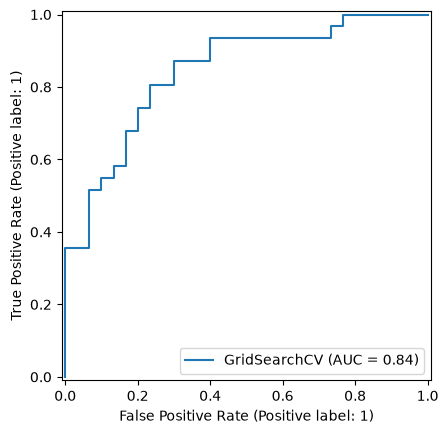

In [69]:
Y_preds=lr_gs.predict(X_test)

RocCurveDisplay.from_estimator(lr_gs, X_test, Y_test)
plt.show()

# this pictutre shows 85 percent area under the curve


# confusion matrix

In [110]:
print(confusion_matrix(Y_test,Y_preds))

[[18 12]
 [ 4 27]]


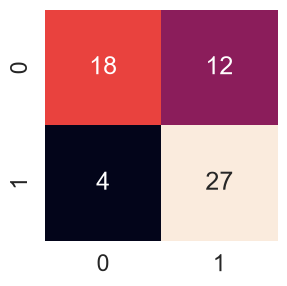

In [73]:
sns.set(font_scale=1.5)

def plot_confusion(Y_test, Y_preds):
    # Plot confusion matrix
    fig, ax = plt.subplots(figsize=(3, 3))
    
    ax = sns.heatmap(
        confusion_matrix(Y_test, Y_preds),
        annot=True,
        cbar=False
    )

plot_confusion(Y_test, Y_preds)

In [74]:
"""1. True Negative (TN)

Actual = 0
Predicted = 0

➡️ There were 18 people who did not have heart disease, and the model correctly predicted that they did not have it.
true prediction

False Positive (FP)

Actual = 0
Predicted = 1

➡️ 12 people did not have heart disease, but the model predicted that they did.

❌ Wrong prediction.

This is called a False Positive.

False Negative (FN)

Actual = 1
Predicted = 0

➡️ 4 people actually had heart disease, but the model predicted no heart disease.

❌ Wrong prediction.

This is called a False Negative.

True Positive (TP)

Actual = 1
Predicted = 1

➡️ 27 people had heart disease, and the model correctly predicted it.

✅ Correct prediction."""

'1. True Negative (TN)\n\nActual = 0\nPredicted = 0\n\n➡️ There were 18 people who did not have heart disease, and the model correctly predicted that they did not have it.\ntrue prediction\n\nFalse Positive (FP)\n\nActual = 0\nPredicted = 1\n\n➡️ 12 people did not have heart disease, but the model predicted that they did.\n\n❌ Wrong prediction.\n\nThis is called a False Positive.\n\nFalse Negative (FN)\n\nActual = 1\nPredicted = 0\n\n➡️ 4 people actually had heart disease, but the model predicted no heart disease.\n\n❌ Wrong prediction.\n\nThis is called a False Negative.\n\nTrue Positive (TP)\n\nActual = 1\nPredicted = 1\n\n➡️ 27 people had heart disease, and the model correctly predicted it.\n\n✅ Correct prediction.'

# Plot the Classification Report

In [76]:

print(classification_report(Y_test, Y_preds))

              precision    recall  f1-score   support

           0       0.82      0.60      0.69        30
           1       0.69      0.87      0.77        31

    accuracy                           0.74        61
   macro avg       0.76      0.74      0.73        61
weighted avg       0.75      0.74      0.73        61



In [78]:
""" FOR 0
precision = 0.82
recall    = 0.60
f1-score  = 0.69
support   = 30

There are 30 actual class-0 cases. Precision = 0.82 → 82%

When the model predicts "No heart disease", it is correct about 82% of the time.Recall = 0.60 → 60%

Out of all the people who actually had no heart disease, the model correctly found 60%.

So, for class 0, the model has good precision but lower recall."""

' FOR 0\nprecision = 0.82\nrecall    = 0.60\nf1-score  = 0.69\nsupport   = 30\n\nThere are 30 actual class-0 cases. Precision = 0.82 → 82%\n\nWhen the model predicts "No heart disease", it is correct about 82% of the time.Recall = 0.60 → 60%\n\nOut of all the people who actually had no heart disease, the model correctly found 60%.\n\nSo, for class 0, the model has good precision but lower recall.'

In [80]:
""" FOR 1
precision = 0.69
recall    = 0.87
f1-score  = 0.77
support   = 31
There are 31 actual class-1 cases.

Precision = 0.69 → 69%

When the model predicts "Heart disease", about 69% of those predictions are correct.

Recall = 0.87 → 87%

Out of all the people who actually had heart disease, the model correctly identified 87%.

 This is important because your model is doing quite well at finding class 1 (heart disease)."""
 

' FOR 1\nprecision = 0.69\nrecall    = 0.87\nf1-score  = 0.77\nsupport   = 31\nThere are 31 actual class-1 cases.\n\nPrecision = 0.69 → 69%\n\nWhen the model predicts "Heart disease", about 69% of those predictions are correct.\n\nRecall = 0.87 → 87%\n\nOut of all the people who actually had heart disease, the model correctly identified 87%.\n\n This is important because your model is doing quite well at finding class 1 (heart disease).'

In [81]:
"""3. F1-score

F1-score combines precision and recall.

For your model:

Class 0 → 0.69
Class 1 → 0.77

Higher F1-score generally means better balance between precision and recall."""

'3. F1-score\n\nF1-score combines precision and recall.\n\nFor your model:\n\nClass 0 → 0.69\nClass 1 → 0.77\n\nHigher F1-score generally means better balance between precision and recall.'

In [82]:
"""4. Support

Support simply tells us how many actual examples belong to each class.

Class 0 = 30
Class 1 = 31
Total   = 61

So your test dataset contains 61 samples."""

'4. Support\n\nSupport simply tells us how many actual examples belong to each class.\n\nClass 0 = 30\nClass 1 = 31\nTotal   = 61\n\nSo your test dataset contains 61 samples.'

In [83]:
"""5. Accuracy = 0.74
accuracy = 0.74

This means your model correctly predicted approximately 74% of the test samples.

From your confusion matrix:

18  12
 4  27

Correct predictions are the diagonal:

18 + 27 = 45

Total:

18 + 12 + 4 + 27 = 61

Therefore:

45 / 61 = 0.738 ≈ 74%, """

'5. Accuracy = 0.74\naccuracy = 0.74\n\nThis means your model correctly predicted approximately 74% of the test samples.\n\nFrom your confusion matrix:\n\n18  12\n 4  27\n\nCorrect predictions are the diagonal:\n\n18 + 27 = 45\n\nTotal:\n\n18 + 12 + 4 + 27 = 61\n\nTherefore:\n\n45 / 61 = 0.738 ≈ 74%, '

In [84]:
"""6. Macro average
macro avg
precision = 0.76
recall    = 0.74
f1-score  = 0.73

Macro average takes the simple average of class 0 and class 1.

For example:

Precision = (0.82 + 0.69) / 2
          = 0.755 ≈ 0.76

It gives equal importance to both classes."""

'6. Macro average\nmacro avg\nprecision = 0.76\nrecall    = 0.74\nf1-score  = 0.73\n\nMacro average takes the simple average of class 0 and class 1.\n\nFor example:\n\nPrecision = (0.82 + 0.69) / 2\n          = 0.755 ≈ 0.76\n\nIt gives equal importance to both classes.'

In [85]:
"""7. Weighted average
weighted avg
precision = 0.75
recall    = 0.74
f1-score  = 0.73

Weighted average also considers the number of samples in each class.

Here the classes are almost equal:

Class 0 → 30
Class 1 → 31

So the weighted average is very close to the macro average."""

'7. Weighted average\nweighted avg\nprecision = 0.75\nrecall    = 0.74\nf1-score  = 0.73\n\nWeighted average also considers the number of samples in each class.\n\nHere the classes are almost equal:\n\nClass 0 → 30\nClass 1 → 31\n\nSo the weighted average is very close to the macro average.'

In [87]:
"""                                                                    summary

Remember these four:

Precision:

When the model predicts positive, how often is it correct?

Recall:

Out of all actual positives, how many did the model find?

F1-score:

Balance between precision and recall.

Support:

Number of actual samples in that class.

Your model

Accuracy = 74%

Class 1 recall = 87% → The model is relatively good at detecting people who actually belong to class 1."""

'                                                                    summary\n\nRemember these four:\n\nPrecision:\n\nWhen the model predicts positive, how often is it correct?\n\nRecall:\n\nOut of all actual positives, how many did the model find?\n\nF1-score:\n\nBalance between precision and recall.\n\nSupport:\n\nNumber of actual samples in that class.\n\nYour model\n\nAccuracy = 74%\n\nClass 1 recall = 87% → The model is relatively good at detecting people who actually belong to class 1.'

In [90]:
lr_gs.best_params_



{'C': np.float64(10000.0), 'solver': 'lbfgs'}

In [91]:
lr=LogisticRegression(C=np.float64(10000.0),
                     solver='lbfgs')

In [93]:
# cross validation accuracy
cv_accuracy=cross_val_score(lr,
                            x,
                            y,
                            cv=7,
                            scoring='accuracy')
cv_accuracy=np.mean(cv_accuracy)
cv_accuracy

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

np.float64(0.8350196315312594)

In [94]:
# cross validation precision
cv_precision=cross_val_score(lr,
                            x,
                            y,
                            cv=7,
                            scoring='precision')
cv_precision=np.mean(cv_precision)
cv_precision

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

np.float64(0.8238851095993953)

In [95]:
# cross validation recall
cv_recall=cross_val_score(lr,
                            x,
                            y,
                            cv=7,
                            scoring='recall')
cv_recall=np.mean(cv_recall)
cv_recall

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

np.float64(0.890527950310559)

In [98]:
cv_f1 = cross_val_score(
    lr,
    x,
    y,
    cv=7,
    scoring='f1'
)

cv_f1 = np.mean(cv_f1)

cv_f1

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.

np.float64(0.8551456238328861)

# Visualizing the Cross validation Matrices


<Axes: title={'center': 'comparision of Matrix'}>

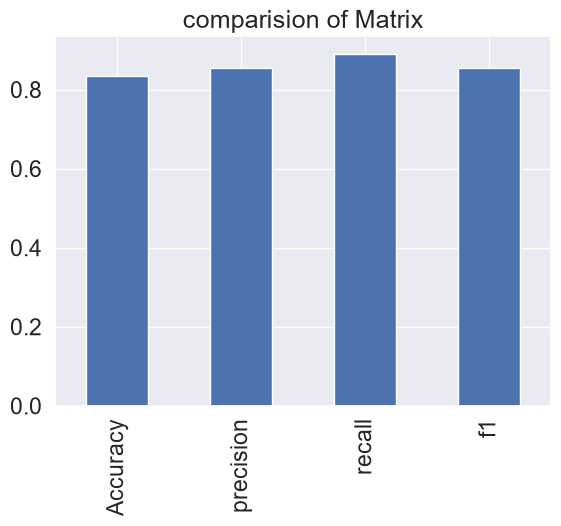

In [100]:
cv_plot=pd.DataFrame({
    "Accuracy" : cv_accuracy,
    "precision" : cv_precision,
    "recall" : cv_recall,
    "f1" : cv_f1
},index=[0])
cv_plot.T.plot.bar(title='comparision of Matrix',
                legend=False)
                     

# Feature Improvement

In [101]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [104]:
# check cofficent
lr.fit(X_train,Y_train)
lr.coef_

C:\Users\hp\Desktop\AI-Corce\cardio_project_1\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([[ 0.02805719, -1.94385725,  0.9099445 , -0.02695696, -0.00220056,
         0.56713972,  0.79313041,  0.04017417, -1.06409339, -0.58300752,
         0.7566328 , -0.73334831, -1.32477718]])

In [107]:
final_coef= dict(zip(df.columns,list(lr.coef_[0])))
final_coef

{'age': np.float64(0.028057193084490745),
 'sex': np.float64(-1.9438572474106108),
 'cp': np.float64(0.9099445044702387),
 'trestbps': np.float64(-0.026956956760924963),
 'chol': np.float64(-0.0022005569319790775),
 'fbs': np.float64(0.567139719216312),
 'restecg': np.float64(0.7931304088398123),
 'thalach': np.float64(0.0401741661953567),
 'exang': np.float64(-1.0640933850710894),
 'oldpeak': np.float64(-0.5830075197388266),
 'slope': np.float64(0.7566328026327839),
 'ca': np.float64(-0.7333483120118335),
 'thal': np.float64(-1.3247771782085467)}

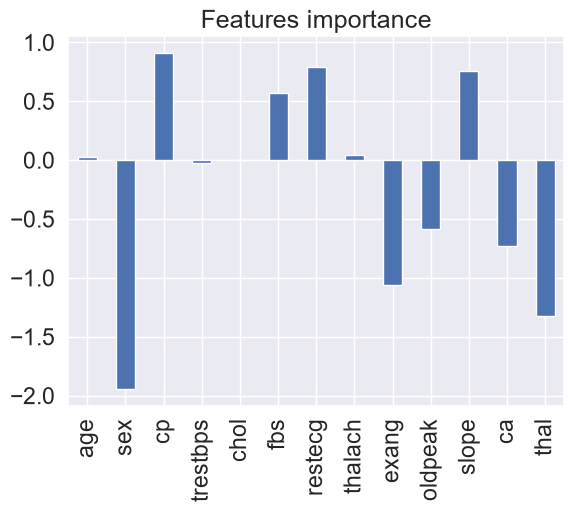

In [109]:
features = pd.DataFrame(final_coef,index=[0])
features.T.plot.bar(title='Features importance',
                legend=False);